In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones medias y desviaciones típicas (en semanas) se adjunta. Las actividades A y H tienen duración fija; las demás son independientes y aproximadamente normales.

In [4]:
pregunta_1 = "1. Dibuje el grafo y enumere las rutas con su duración media y su varianza. ¿Cuál es la ruta crítica en media?  "
pregunta_2 = "2. Las dos rutas comparten A y H. Calcule la media y la varianza de la *diferencia* entre la duración de la ruta que pasa por B y la que pasa por E. ¿Qué probabilidad hay de que la segunda resulte más larga (es decir, de que sea ella la crítica)?  "
pregunta_3 = "3. Calcule la probabilidad de terminar el proyecto en 20 semanas o menos (a) con el método PERT (sólo la ruta crítica) y (b) de forma exacta, usando que las dos cadenas son independientes: el proyecto termina a tiempo si *las dos* cadenas terminan a tiempo.  "
pregunta_4 = "4. ¿Cuál de las dos probabilidades es mayor? ¿Es general ese sentido del error del método PERT?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje el grafo y enumere las rutas con su duración media y su varianza. ¿Cuál es la ruta crítica en media?  

2. Las dos rutas comparten A y H. Calcule la media y la varianza de la *diferencia* entre la duración de la ruta que pasa por B y la que pasa por E. ¿Qué probabilidad hay de que la segunda resulte más larga (es decir, de que sea ella la crítica)?  

3. Calcule la probabilidad de terminar el proyecto en 20 semanas o menos (a) con el método PERT (sólo la ruta crítica) y (b) de forma exacta, usando que las dos cadenas son independientes: el proyecto termina a tiempo si *las dos* cadenas terminan a tiempo.  

4. ¿Cuál de las dos probabilidades es mayor? ¿Es general ese sentido del error del método PERT?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 3       , 0                 ),
    ('B'     , 'A'        , 7       , 0.8               ),
    ('C'     , 'B'        , 3       , 0.5               ),
    ('D'     , 'C'        , 4       , 0.5               ),
    ('E'     , 'A'        , 7       , 1                 ),
    ('F'     , 'E'        , 6       , 1                 ),
    ('H'     , 'D,F'      , 2       , 0                 ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,3,0.0
B,A,7,0.8
C,B,3,0.5
D,C,4,0.5
E,A,7,1.0
F,E,6,1.0
H,"D,F",2,0.0


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
plazo = 20

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Dibuje el grafo y enumere las rutas con su duración media y su varianza. ¿Cuál es la ruta crítica en media?  

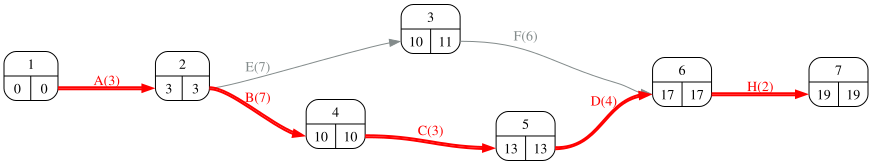

In [8]:
#| fig-cap: "Grafo PERT"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [9]:
#| tbl-cap: "Media y varianza de cada ruta"
#| label: tbl-rutas
R = proyecto.path_matrix(dummies=False)
medias = detalle_rutas(R, datos_proyecto['duration'][R.columns], 'media')
varianzas = detalle_rutas(R, datos_proyecto['variance'][R.columns], 'varianza', 3)
pd.concat([medias, varianzas.drop(columns='actividades')], axis=1)

,actividades,media = suma,media,varianza = suma,varianza
Route_1,A - B - C - D - H,A(3) + B(7) + C(3) + D(4) + H(2) = 19,19.0,A(0.000) + B(0.640) + C(0.250) + D(0.250) + H(...,1.14
Route_2,A - E - F - H,A(3) + E(7) + F(6) + H(2) = 18,18.0,A(0.000) + E(1.000) + F(1.000) + H(0.000) = 2.000,2.0


In [10]:
ruta1 = R.index[R['B'] == 1][0]; ruta2 = R.index[R['E'] == 1][0]
mu1, mu2 = float(medias.loc[ruta1, 'media']), float(medias.loc[ruta2, 'media'])
v1, v2 = float(varianzas.loc[ruta1, 'varianza']), float(varianzas.loc[ruta2, 'varianza'])
Markdown(f'En media la ruta crítica es {ruta1 if mu1 >= mu2 else ruta2} ({max(mu1, mu2):.0f} semanas frente a {min(mu1, mu2):.0f}).')

En media la ruta crítica es Route_1 (19 semanas frente a 18).

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Las dos rutas comparten A y H. Calcule la media y la varianza de la *diferencia* entre la duración de la ruta que pasa por B y la que pasa por E. ¿Qué probabilidad hay de que la segunda resulte más larga (es decir, de que sea ella la crítica)?  

A y H están en las dos rutas y son fijas: en la diferencia $L_2 - L_1$ se cancelan. La diferencia de dos normales independientes es normal con media la diferencia de medias y varianza la *suma* de varianzas.

In [12]:
mu_dif, var_dif = mu2 - mu1, v1 + v2
sigma_dif = np.sqrt(var_dif)
p_ruta2_critica = 1 - norm.cdf((0 - mu_dif) / sigma_dif)
Markdown(f'''L₂ − L₁ ~ N({mu2:.0f} − {mu1:.0f} = {mu_dif:.0f}, {v1:.3f} + {v2:.3f} = {var_dif:.3f}), σ = {sigma_dif:.3f}. P(L₂ > L₁) = P(Z > (0 − ({mu_dif:.0f})) / {sigma_dif:.3f}) = 1 − Φ({-mu_dif / sigma_dif:.3f}) = {p_ruta2_critica:.4f}: la ruta «no crítica» resulta ser la más larga el {p_ruta2_critica * 100:.1f} % de las veces.''')

L₂ − L₁ ~ N(18 − 19 = -1, 1.140 + 2.000 = 3.140), σ = 1.772. P(L₂ > L₁) = P(Z > (0 − (-1)) / 1.772) = 1 − Φ(0.564) = 0.2863: la ruta «no crítica» resulta ser la más larga el 28.6 % de las veces.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Calcule la probabilidad de terminar el proyecto en 20 semanas o menos (a) con el método PERT (sólo la ruta crítica) y (b) de forma exacta, usando que las dos cadenas son independientes: el proyecto termina a tiempo si *las dos* cadenas terminan a tiempo.  

In [14]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
sigma_pert = np.sqrt(v1 if mu1 >= mu2 else v2)
p_pert = norm.cdf((plazo - duracion_media) / sigma_pert)
dA, dH = float(datos_proyecto.loc['A', 'duration']), float(datos_proyecto.loc['H', 'duration'])
limite = plazo - dA - dH   # lo que puede durar cada cadena intermedia
p1 = norm.cdf((limite - (mu1 - dA - dH)) / np.sqrt(v1))
p2 = norm.cdf((limite - (mu2 - dA - dH)) / np.sqrt(v2))
p_exacta = p1 * p2
Markdown(f'''(a) PERT: z = ({plazo} − {duracion_media}) / {sigma_pert:.3f} = {(plazo - duracion_media) / sigma_pert:.3f}, P = {p_pert:.4f}.

(b) Exacta: cada cadena intermedia debe durar como mucho {plazo} − {dA:.0f} − {dH:.0f} = {limite:.0f}; P(cadena 1 ≤ {limite:.0f}) = {p1:.4f}, P(cadena 2 ≤ {limite:.0f}) = {p2:.4f}, y por independencia P(T ≤ {plazo}) = {p1:.4f} × {p2:.4f} = {p_exacta:.4f}.''')

(a) PERT: z = (20 − 19) / 1.068 = 0.937, P = 0.8255.

(b) Exacta: cada cadena intermedia debe durar como mucho 20 − 3 − 2 = 15; P(cadena 1 ≤ 15) = 0.8255, P(cadena 2 ≤ 15) = 0.9214, y por independencia P(T ≤ 20) = 0.8255 × 0.9214 = 0.7606.

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. ¿Cuál de las dos probabilidades es mayor? ¿Es general ese sentido del error del método PERT?  

In [16]:
Markdown(f'''PERT da {p_pert:.4f} y el cálculo exacto {p_exacta:.4f}: PERT es optimista. Es general: el máximo de varias rutas es siempre mayor o igual que la ruta crítica sola, luego P(máx ≤ t) ≤ P(ruta crítica ≤ t). El error es grande cuando hay rutas casi críticas con varianza apreciable, como aquí.''')

PERT da 0.8255 y el cálculo exacto 0.7606: PERT es optimista. Es general: el máximo de varias rutas es siempre mayor o igual que la ruta crítica sola, luego P(máx ≤ t) ≤ P(ruta crítica ≤ t). El error es grande cuando hay rutas casi críticas con varianza apreciable, como aquí.